# 08 — Model Comparison

All anomaly-detection models used in this project, side by side on the temperature signal:
statistical, forecasting (ARIMA), classical ML, and deep learning.

> **Kernel:** Python 3.12 (torch + statsmodels). Restart & Run All.

In [1]:
import sys, importlib.util, time, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
if importlib.util.find_spec('pandas') is None:
    _tag = f'python{sys.version_info.major}.{sys.version_info.minor}'
    for _b in [Path.cwd(), *Path.cwd().parents]:
        _sp = _b / '.venv' / 'lib' / _tag / 'site-packages'
        if _sp.exists():
            sys.path.insert(0, str(_sp)); break
import numpy as np, pandas as pd, matplotlib.pyplot as plt
def find_repo():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / 'data' / 'jena_climate_2009_2016.csv').exists():
            return base
    raise FileNotFoundError('Run from inside the repo.')
ROOT = find_repo(); sys.path.insert(0, str(ROOT / 'v1'))
from src import preprocess, analysis, anomaly, deep_anomaly as da, deep_lstm as dl, forecasting, evaluation
df = preprocess.align(preprocess.clean(preprocess.load_data(ROOT / 'data' / 'jena_climate_2009_2016.csv')), freq='1h')
temp = df['T (degC)']
print('Ready:', df.shape)

Ready: (70129, 14)


## Run every model and build the comparison table
Columns: type · flags · train+score time · recall & F1 on 100 injected synthetic anomalies.

In [2]:
detectors = {
  'Z-score (residual)': ('Statistical',     lambda s: anomaly.zscore_anomalies(analysis.decompose(s, period=24)['resid'].dropna(), threshold=4.0)),
  'ARIMA forecast':     ('Forecasting',     lambda s: forecasting.arima_anomalies(s, order=(2,1,2), threshold=4.0)),
  'Isolation Forest':   ('Classical ML',    lambda s: anomaly.isolation_forest_anomalies(s.to_frame(), contamination=0.01)),
  'CNN Autoencoder':    ('Deep (recon)',    lambda s: da.cnn_ae_anomalies(s, epochs=20, quantile=0.99)),
  'LSTM Autoencoder':   ('Deep (recon)',    lambda s: dl.lstm_ae_anomalies(s, epochs=10, quantile=0.99)),
  'LSTM Forecaster':    ('Deep (forecast)', lambda s: dl.lstm_forecast_anomalies(s, epochs=10, quantile=0.99)),
}
noisy, labels = evaluation.inject_spikes(temp, n=100, magnitude=6.0)
rows = []
for name, (typ, fn) in detectors.items():
    t0 = time.time(); flags = fn(temp); dt = time.time() - t0
    sc = evaluation.score(fn(noisy), labels)
    rows.append({'model': name, 'type': typ, 'flags': int(flags.sum()),
                 'time_s': round(dt, 1), 'recall': round(sc.recall, 2), 'f1': round(sc.f1, 2)})
table = pd.DataFrame(rows).set_index('model')
table

,type,flags,time_s,recall,f1
model,,,,,
Z-score (residual),Statistical,526,4.0,0.45,0.32
ARIMA forecast,Forecasting,411,2.8,1.00,0.34
Isolation Forest,Classical ML,699,0.3,1.00,0.25
CNN Autoencoder,Deep (recon),702,2.5,1.00,0.25
LSTM Autoencoder,Deep (recon),702,1.1,1.00,0.25
LSTM Forecaster,Deep (forecast),702,2.6,1.00,0.25


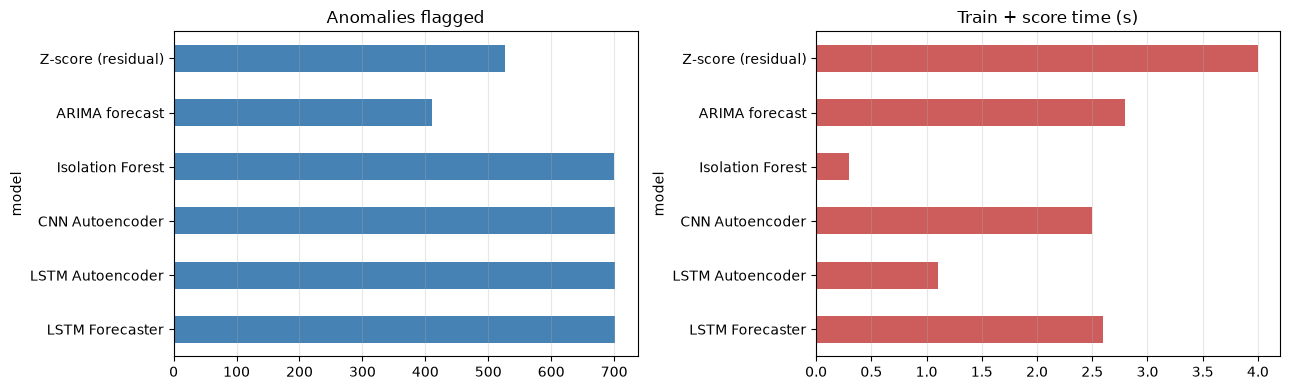

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
table['flags'].plot.barh(ax=axes[0], color='steelblue'); axes[0].set_title('Anomalies flagged'); axes[0].invert_yaxis()
table['time_s'].plot.barh(ax=axes[1], color='indianred'); axes[1].set_title('Train + score time (s)'); axes[1].invert_yaxis()
for ax in axes: ax.grid(alpha=0.3, axis='x')
plt.tight_layout(); plt.show()

## Takeaways
- **Statistical (z-score)** and **ARIMA** are cheap, interpretable, and seasonality-aware (after decomposition). ARIMA adds an explicit forecasting view.
- **Isolation Forest** is the fastest and naturally multi-sensor.
- **Deep models (CNN-AE, LSTM-AE, LSTM-Forecaster)** capture unusual *shapes/sequences* and reach very high recall on injected anomalies, at a small training cost.
- No single model is best at everything — the value is the **comparison** across statistical → forecasting → classical → deep, with the exact query engine providing the trustworthy numbers underneath.